In [24]:
#Simulate 100,000 years

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
project_root = cwd if (cwd / "config").exists() else cwd.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.annual_loss_simulation import (
    simulate_annual_losses,
    summarize_annual_losses,
    exceedance_probabilities,
)

import importlib
import src.annual_loss_simulation as annual_module

importlib.reload(annual_module)

simulate_annual_losses = annual_module.simulate_annual_losses

annual = simulate_annual_losses(
    n_years=100_000,
    seed=20261025,
)

print("Simulated years:", len(annual))
print("Successful incidents:", annual["successful_incident_count"].sum())

display(annual.head(10))

Simulated years: 100000
Successful incidents: 22159


,year_id,campaign_count,successful_incident_count,primary_loss_usd,secondary_response_planning_loss_usd,secondary_fines_judgement_loss_usd,secondary_reputation_loss_usd,total_annual_loss_usd,maximum_single_event_loss_usd
0,1,1,0,0.000000,0.000000,0.000000,0.0,0.000000e+00,0.000000e+00
1,2,2,0,0.000000,0.000000,0.000000,0.0,0.000000e+00,0.000000e+00
2,3,4,1,106344.368187,92635.843005,0.000000,630000.0,8.289802e+05,8.289802e+05
3,4,1,0,0.000000,0.000000,0.000000,0.0,0.000000e+00,0.000000e+00
4,5,2,0,0.000000,0.000000,0.000000,0.0,0.000000e+00,0.000000e+00
5,6,5,1,151918.564672,237128.655224,488808.180238,630000.0,1.507855e+06,1.507855e+06
6,7,3,0,0.000000,0.000000,0.000000,0.0,0.000000e+00,0.000000e+00
7,8,5,0,0.000000,0.000000,0.000000,0.0,0.000000e+00,0.000000e+00
8,9,2,1,253546.294627,276063.895720,0.000000,1470000.0,1.999610e+06,1.999610e+06
9,10,2,0,0.000000,0.000000,0.000000,0.0,0.000000e+00,0.000000e+00


In [25]:
print("Maximum single-event column exists:",
      "maximum_single_event_loss_usd" in annual.columns)

Maximum single-event column exists: True


In [16]:
#Annual risk metrics

summary = summarize_annual_losses(annual)

# Convert to object dtype to allow formatted strings
formatted_summary = summary.astype(object).copy()

for metric in formatted_summary.index:
    value = formatted_summary[metric]

    if metric.endswith("_usd"):
        formatted_summary[metric] = f"${value:,.2f}"
    elif metric.startswith("probability_"):
        formatted_summary[metric] = f"{value:.2%}"
    elif metric == "simulated_years":
        formatted_summary[metric] = f"{value:,.0f}"
    else:
        formatted_summary[metric] = f"{value:,.4f}"

display(formatted_summary.to_frame(name="Value"))

,Value
simulated_years,"100,000"
mean_campaigns_per_year,3.0018
mean_incidents_per_year,0.2216
probability_any_incident,19.88%
aal_usd,"$272,725.04"
median_annual_loss_usd,$0.00
var_90_usd,"$984,691.54"
var_95_usd,"$1,730,117.35"
var_99_usd,"$3,793,561.68"
tvar_90_usd,"$2,167,827.99"


,incidents_per_year,years,proportion
0,0,80116,0.80116
1,1,17780,0.17780
2,2,1945,0.01945
3,3,148,0.00148
4,4,10,0.00010
5,5,1,0.00001


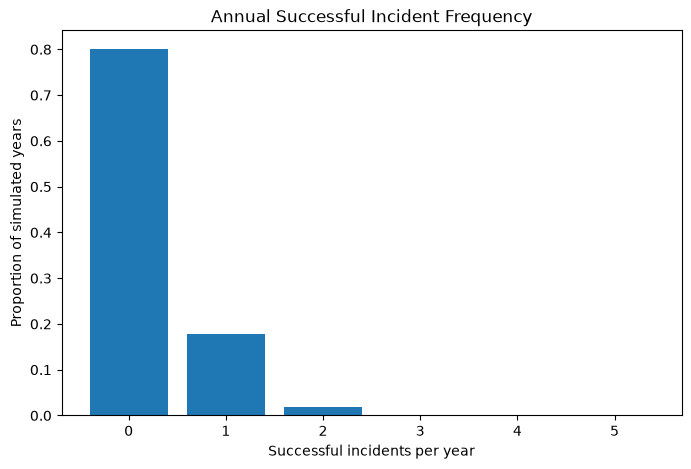

In [17]:
#Annual incident count distribution 

counts = annual["successful_incident_count"]

frequency_table = (
    counts.value_counts()
    .sort_index()
    .rename_axis("incidents_per_year")
    .reset_index(name="years")
)

frequency_table["proportion"] = (
    frequency_table["years"] / len(annual)
)

display(frequency_table)

plt.figure(figsize=(8, 5))
plt.bar(
    frequency_table["incidents_per_year"],
    frequency_table["proportion"],
)

plt.xlabel("Successful incidents per year")
plt.ylabel("Proportion of simulated years")
plt.title("Annual Successful Incident Frequency")
plt.show()

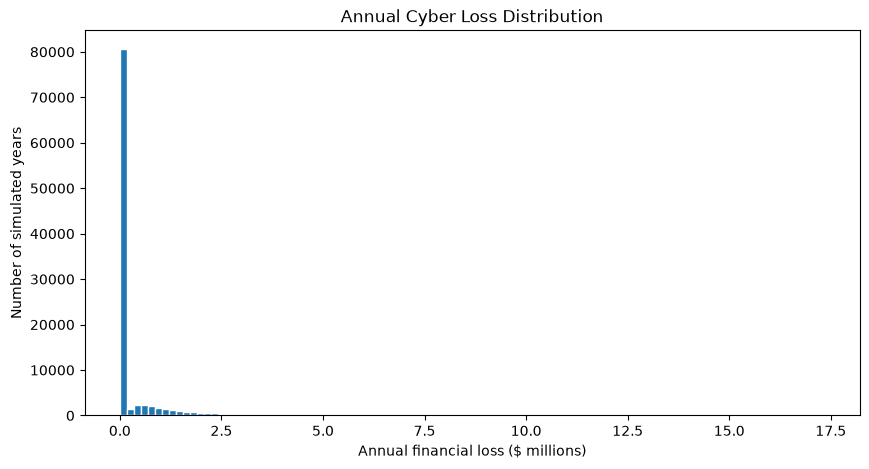

In [18]:
#Annual loss distribution

losses_m = annual["total_annual_loss_usd"] / 1_000_000

plt.figure(figsize=(10, 5))

plt.hist(
    losses_m,
    bins=100,
    edgecolor="white",
)

plt.xlabel("Annual financial loss ($ millions)")
plt.ylabel("Number of simulated years")
plt.title("Annual Cyber Loss Distribution")
plt.show()

#Because most years have zero loss, the histogram will have a large spike at zero.

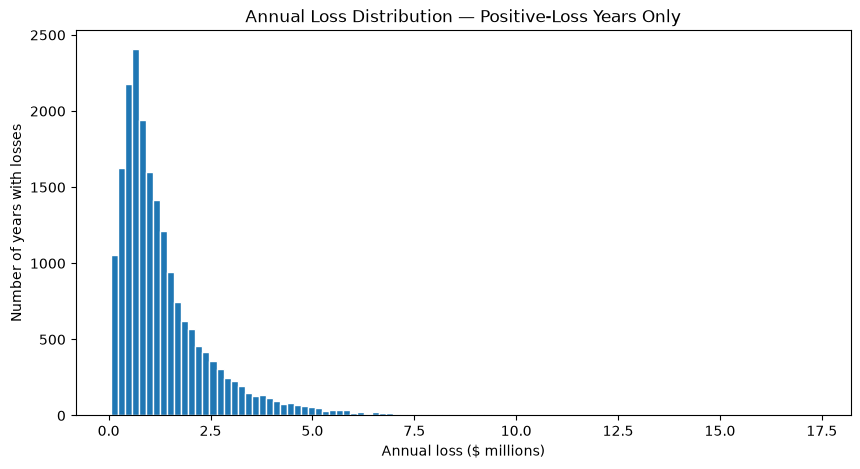

In [19]:
#Because most years have zero loss, the histogram has a large spike at zero.
#Visualize the positive-loss distribution separately

positive_losses_m = losses_m[losses_m > 0]

plt.figure(figsize=(10, 5))

plt.hist(
    positive_losses_m,
    bins=100,
    edgecolor="white",
)

plt.xlabel("Annual loss ($ millions)")
plt.ylabel("Number of years with losses")
plt.title("Annual Loss Distribution — Positive-Loss Years Only")
plt.show()

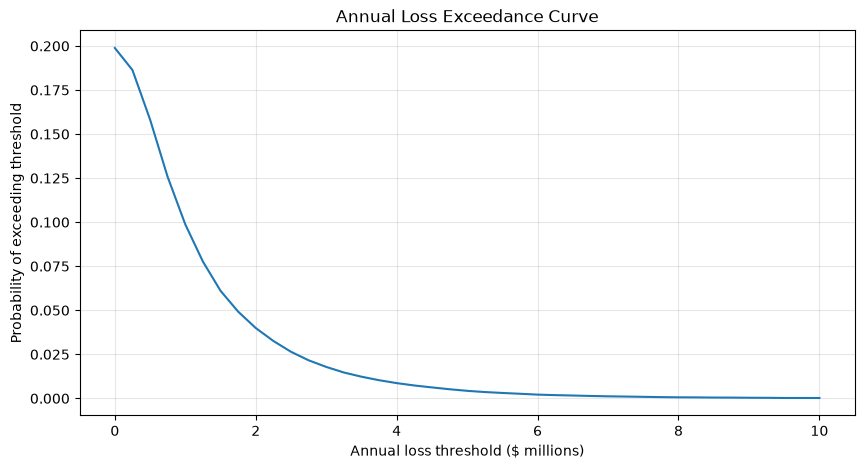

In [20]:
#Annual exceedance probability
#Answers questions such as: What is the probability that NovaFlow experiences more than $2 million in cyber losses in a given year?

thresholds = np.arange(
    0,
    10_000_001,
    250_000,
)

exceedance = exceedance_probabilities(
    annual,
    thresholds=thresholds,
)

plt.figure(figsize=(10, 5))

plt.plot(
    exceedance["threshold_usd"] / 1_000_000,
    exceedance["probability_exceeding"],
)

plt.xlabel("Annual loss threshold ($ millions)")
plt.ylabel("Probability of exceeding threshold")
plt.title("Annual Loss Exceedance Curve")
plt.grid(alpha=0.3)
plt.show()

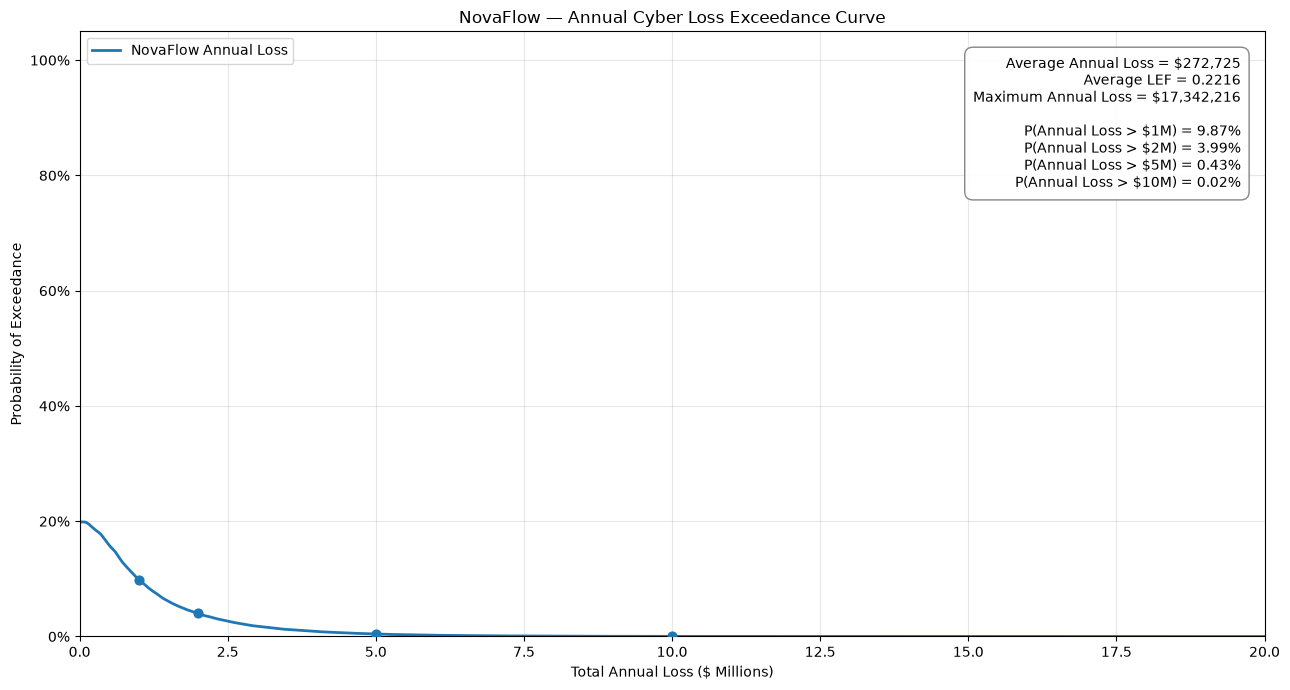

In [21]:
# Annual Loss Exceedance Curve with Key Statistics

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np

losses = annual["total_annual_loss_usd"].to_numpy()

# Exceedance thresholds
thresholds = np.linspace(0, 20_000_000, 500)

exceedance_probs = np.array([
    np.mean(losses > threshold)
    for threshold in thresholds
])

# Selected thresholds for reporting
selected_thresholds = [
    1_000_000,
    2_000_000,
    5_000_000,
    10_000_000,
]

selected_probs = {
    threshold: np.mean(losses > threshold)
    for threshold in selected_thresholds
}

# Summary statistics
aal = losses.mean()
average_lef = annual["successful_incident_count"].mean()
maximum_annual_loss = losses.max()

# Statistics box
stats_text = (
    f"Average Annual Loss = ${aal:,.0f}\n"
    f"Average LEF = {average_lef:.4f}\n"
    f"Maximum Annual Loss = ${maximum_annual_loss:,.0f}\n"
    "\n"
    + "\n".join(
        f"P(Annual Loss > ${t / 1e6:g}M) = {p:.2%}"
        for t, p in selected_probs.items()
    )
)

fig, ax = plt.subplots(figsize=(13, 7))

ax.plot(
    thresholds / 1e6,
    exceedance_probs,
    linewidth=2,
    label="NovaFlow Annual Loss",
)

# Mark selected thresholds on the curve
ax.scatter(
    np.array(selected_thresholds) / 1e6,
    list(selected_probs.values()),
    s=40,
    zorder=5,
)

# Statistics box
ax.text(
    0.98,
    0.96,
    stats_text,
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment="top",
    horizontalalignment="right",
    bbox=dict(
        boxstyle="round,pad=0.6",
        facecolor="white",
        edgecolor="gray",
        alpha=0.95,
    ),
)

ax.set_xlabel("Total Annual Loss ($ Millions)")
ax.set_ylabel("Probability of Exceedance")
ax.set_title("NovaFlow — Annual Cyber Loss Exceedance Curve")

ax.set_xlim(0, 20)
ax.set_ylim(0, 1.05)

ax.yaxis.set_major_formatter(
    mtick.PercentFormatter(xmax=1)
)

ax.grid(alpha=0.3)
ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

,category,aal_usd,share
0,Primary response,32581.547860,0.119467
1,Secondary response & planning,41521.005146,0.152245
2,Secondary fines & judgments,24895.783981,0.091285
3,Secondary reputation,173726.700000,0.637003


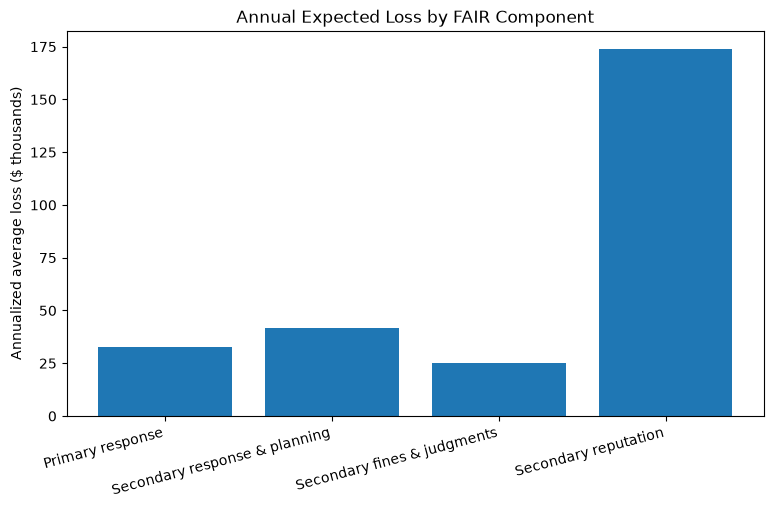

In [22]:
from src.incident_simulation import LOSS_COLUMNS

labels = [
    "Primary response",
    "Secondary response & planning",
    "Secondary fines & judgments",
    "Secondary reputation",
]

mean_annual_components = (
    annual[LOSS_COLUMNS].mean()
)

component_table = pd.DataFrame({
    "category": labels,
    "aal_usd": mean_annual_components.to_numpy(),
})

component_table["share"] = (
    component_table["aal_usd"]
    / component_table["aal_usd"].sum()
)

display(component_table)

plt.figure(figsize=(9, 5))
plt.bar(
    component_table["category"],
    component_table["aal_usd"] / 1000,
)

plt.ylabel("Annualized average loss ($ thousands)")
plt.title("Annual Expected Loss by FAIR Component")
plt.xticks(rotation=15, ha="right")
plt.show()

In [27]:
#Final Consolidated FAIR Risk Summary

import pandas as pd
import numpy as np

from src.annual_loss_simulation import empirical_tvar

losses = annual["total_annual_loss_usd"].to_numpy()

# Main statistics
n_years = len(annual)
maximum_single_event = annual[
    "maximum_single_event_loss_usd"
].max()

maximum_annual_loss = losses.max()
average_lef = annual["successful_incident_count"].mean()
probability_any_incident = np.mean(
    annual["successful_incident_count"] > 0
)

aal = losses.mean()
median_annual_loss = np.median(losses)

# VaR and TVaR
var_levels = [0.90, 0.95, 0.99]

# Exceedance thresholds
thresholds = [
    1_000_000,
    2_000_000,
    5_000_000,
    10_000_000,
]

# Build summary
results = [
    ("Simulated Years", f"{n_years:,}"),
    ("Maximum Single Event Loss",
     f"${maximum_single_event:,.2f}"),
    ("Maximum Total Annual Loss",
     f"${maximum_annual_loss:,.2f}"),
    ("Average LEF",
     f"{average_lef:.4f}"),
    ("P(At Least One Incident)",
     f"{probability_any_incident:.2%}"),
    ("Annual Average Loss (AAL)",
     f"${aal:,.2f}"),
    ("Median Annual Loss",
     f"${median_annual_loss:,.2f}"),
]

# VaR
for level in var_levels:
    results.append((
        f"VaR {level:.0%}",
        f"${np.quantile(losses, level):,.2f}",
    ))

# TVaR
for level in var_levels:
    results.append((
        f"TVaR {level:.0%}",
        f"${empirical_tvar(losses, level):,.2f}",
    ))

# Exceedance probabilities
for threshold in thresholds:
    probability = np.mean(losses > threshold)

    results.append((
        f"P(Annual Loss > ${threshold / 1e6:g}M)",
        f"{probability:.2%}",
    ))

final_summary = pd.DataFrame(
    results,
    columns=["Risk Metric", "Value"],
)

display(final_summary)

,Risk Metric,Value
0,Simulated Years,"100,000"
1,Maximum Single Event Loss,"$16,312,434.43"
2,Maximum Total Annual Loss,"$17,342,216.37"
3,Average LEF,0.2216
4,P(At Least One Incident),19.88%
5,Annual Average Loss (AAL),"$272,725.04"
6,Median Annual Loss,$0.00
7,VaR 90%,"$984,691.54"
8,VaR 95%,"$1,730,117.35"
9,VaR 99%,"$3,793,561.68"
